## Hierarchical Clustering

This notebook accompanies the **Clustering** slides that we are discussing in class. It picks up where the K-means notebook left off. We cluster Palmer penguins using four body measurements, **without** telling the algorithms the species. Species is used only to check how well the clusters line up with real structure. In a real clustering problem we would have no ability to check this.

*AI disclosure: The code in this notebook was generated with the assistance of Claude. I gave Claude a pretty detailed prompt, then I went through and modified both the code itself and the explanations provided. I made sure I could execute and validate the output for code written.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.datasets import make_moons
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform

# Same colors as the slides: orange, blue, teal, purple
PALETTE = ["#E57100", "#3E6FB0", "#2A9D8F", "#8E4FA0"]
sns.set_theme(style="white", palette=PALETTE)

### Setup: data and objects from the K-means notebook

Load the penguins and standardize the four measurements, as before. We also recreate three things from the K-means notebook that we compare against below: the two standardized features (bill length and depth), the K = 3 K-means clusters (labeled A, B, C), and the two-moons data with its K-means fit.

In [2]:
penguins = pd.read_csv("../data/penguins.csv")
feats = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

# Keep the penguins with all four measurements
df = penguins.dropna(subset=feats).reset_index(drop=True)
X = df[feats]

scaler = StandardScaler()
Xs = scaler.fit_transform(X)   # a NumPy array: 342 rows x 4 standardized features

# Two standardized features (bill length and depth)
Z2 = StandardScaler().fit_transform(df[["bill_length_mm", "bill_depth_mm"]])
print(df.shape)

(342, 8)


In [3]:
def renumber(labels, values, ascending=True):
    # Renumber clusters 1, 2, 3, ... in order of the average of `values` within each cluster.
    # Returns the new labels and `order`, the old cluster numbers listed in their new order.
    order = pd.Series(np.asarray(values)).groupby(np.asarray(labels)).mean().sort_values(ascending=ascending).index.to_numpy()
    new_number = {old: i + 1 for i, old in enumerate(order)}
    return np.array([new_number[k] for k in labels]), order


# K-means with K = 3, clusters named A, B, C in order of average bill depth
km = KMeans(n_clusters=3, n_init=20, random_state=0).fit(Xs)
km_numbers, km_order = renumber(km.labels_, df["bill_depth_mm"])
df["kmeans"] = np.array(list("ABC"))[km_numbers - 1]

# Two interlocking half-moons (simulated), and K-means with K = 2
Xm, _ = make_moons(n_samples=300, noise=0.06, random_state=1)
moon_km = KMeans(n_clusters=2, n_init=20, random_state=0).fit(Xm)

### Example dendrogram (slide 48)

We sample 8 penguins (3 Adelie, 2 Chinstrap, 3 Gentoo) and use the same two standardized features as in Part 1.

In [4]:
species_code = df["species"].map({"Adelie": 0, "Chinstrap": 1, "Gentoo": 2}).to_numpy()

rng = np.random.default_rng(11)
toy_idx = np.concatenate([rng.choice(np.where(species_code == s)[0], n, replace=False)
                          for s, n in [(0, 3), (1, 2), (2, 3)]])
P = Z2[toy_idx]
Z_toy = linkage(P, method="complete")   # complete linkage, Euclidean distance

In [5]:
Z_toy

array([[ 5.        ,  6.        ,  0.55029756,  2.        ],
       [ 3.        ,  4.        ,  0.61228157,  2.        ],
       [ 0.        ,  2.        ,  0.69235082,  2.        ],
       [ 7.        ,  8.        ,  0.75446369,  3.        ],
       [ 1.        , 10.        ,  1.40429553,  3.        ],
       [ 9.        , 11.        ,  2.74977688,  5.        ],
       [12.        , 13.        ,  3.10726129,  8.        ]])

`linkage` returns one row per merge. The first two columns are the clusters being merged: ids `0`–`7` are the original points, and id `8 + r` is the cluster created in row `r`. The third column is the merge height, and the fourth is the size of the new cluster. Below we relabel points 1–8 to match the plot.

In [6]:
def describe_merges(Z, n):
    members = {i: [i + 1] for i in range(n)}
    rows = []
    for r, (a, b, h, size) in enumerate(Z):
        a, b = int(a), int(b)
        members[n + r] = members[a] + members[b]
        rows.append({"merge": r + 1, "joins": f"{sorted(members[a])} + {sorted(members[b])}",
                     "height": round(h, 2), "new size": int(size),
                     "K after merge": n - (r + 1)})
    return pd.DataFrame(rows).set_index("merge")

describe_merges(Z_toy, n=8)

,joins,height,new size,K after merge
merge,,,,
1,[6] + [7],0.55,2,7
2,[4] + [5],0.61,2,6
3,[1] + [3],0.69,2,5
4,"[8] + [6, 7]",0.75,3,4
5,"[2] + [1, 3]",1.40,3,3
6,"[4, 5] + [6, 7, 8]",2.75,5,2
7,"[1, 2, 3] + [4, 5, 6, 7, 8]",3.11,8,1


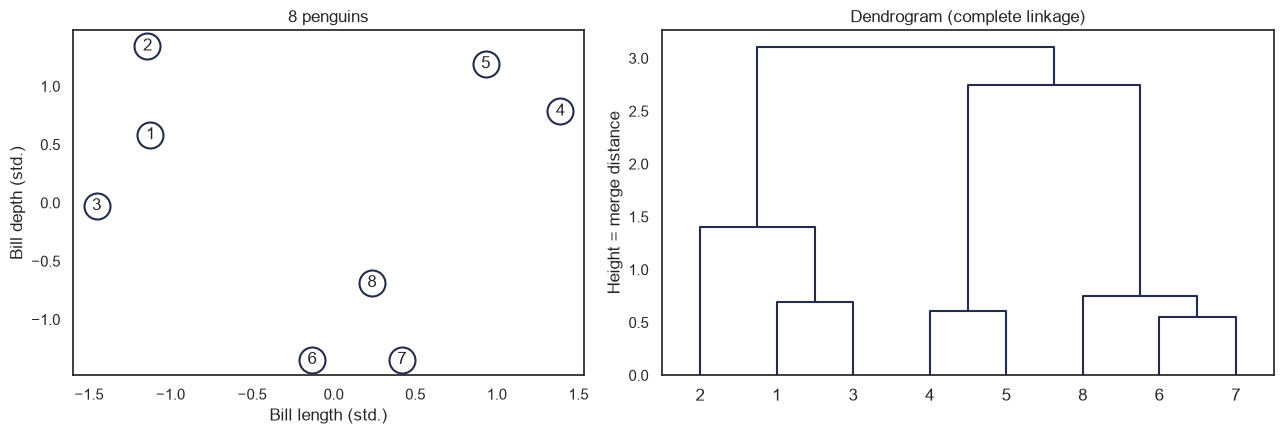

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.2]})
axes[0].scatter(P[:, 0], P[:, 1], s=350, facecolor="white", edgecolor="#232D4B", lw=1.5)
for i, (a, b) in enumerate(P):
    axes[0].text(a, b, str(i + 1), ha="center", va="center", fontsize=12)
axes[0].set_xlabel("Bill length (std.)")
axes[0].set_ylabel("Bill depth (std.)")
axes[0].set_title("8 penguins")

dendrogram(Z_toy, labels=[str(i + 1) for i in range(8)], color_threshold=0,
           above_threshold_color="#232D4B", ax=axes[1])
axes[1].set_ylabel("Height = merge distance")
axes[1].set_title("Dendrogram (complete linkage)")
plt.tight_layout()
plt.show()

**Reading a dendrogram.** Judge similarity by the **height** where two leaves join, not by how close they sit horizontally. In the example above, leaves 3 and 4 are neighbors at the bottom, yet they only join at the very top of the dendrogram. We can also see this from the plot on the left.

### Gower distance example calculation for mixed data (slides 51–52)

Euclidean distance needs numeric features. Gower distance handles numeric and categorical variables by giving each variable a distance between 0 and 1 and averaging:

$$d(i,j) = \frac{\sum_{k} w_k\, d_{ijk}}{\sum_k w_k}, \qquad
d_{ijk} = \begin{cases} \dfrac{|x_{ik} - x_{jk}|}{\max(x_k) - \min(x_k)} & \text{numeric} \\[1ex] 0 \text{ if } x_{ik} = x_{jk}, \ 1 \text{ otherwise} & \text{categorical} \end{cases}$$

We use equal weights ($w_k = 1$). There is a `gower` package on PyPI, but it is only a few lines of NumPy to code by hand. In addition, there are a few cluses that we should beware of this package:

1. It has only one maintainer: https://pypi.org/project/gower/
2. It was last updated 4 years ago: https://github.com/wwwjk366/gower

In [8]:
# Note that this function expects the full dataset
def gower_matrix(data, numeric, categorical):
    n = len(data)
    D = np.zeros((n, n))
    for col in numeric:
        x = data[col].to_numpy(dtype=float)
        D += np.abs(x[:, None] - x[None, :]) / (x.max() - x.min())   # 0-1 by the range
    for col in categorical:
        x = data[col].to_numpy()
        D += (x[:, None] != x[None, :]).astype(float)                 # 0 = match, 1 = differ
    return D / (len(numeric) + len(categorical))

**Slide 52 example** We are going to sample two penguins: bill length, body mass, island, and sex. Ranges come from the 333 penguins with no missing values.

In [9]:
full = penguins.dropna().reset_index(drop=True)   # 333 rows (sex is missing for a few)
a = 0                                              # an Adelie from Torgersen
b = full.index[(full["species"] == "Chinstrap") & (full["bill_length_mm"] == 50.0)
               & (full["body_mass_g"] == 3900)][0]
cols = ["bill_length_mm", "body_mass_g", "island", "sex"]
full.loc[[a, b], ["species"] + cols]

,species,bill_length_mm,body_mass_g,island,sex
0,Adelie,39.1,3750.0,Torgersen,male
266,Chinstrap,50.0,3900.0,Dream,male


In [10]:
G_ex = gower_matrix(full, numeric=["bill_length_mm", "body_mass_g"], categorical=["island", "sex"])
print(f"Gower distance between the two penguins: {G_ex[a, b]:.3f}")

Gower distance between the two penguins: 0.360


In [11]:
# Here we can examine the matrix itself if we choose
G_ex

array([[0.        , 0.25710859, 0.29563131, ..., 0.34719066, 0.38066919,
        0.6026452 ],
       [0.25710859, 0.        , 0.04546717, ..., 0.59355429, 0.62356061,
        0.34900884],
       [0.29563131, 0.04546717, 0.        , ..., 0.62100379, 0.65448232,
        0.37645833],
       ...,
       [0.34719066, 0.59355429, 0.62100379, ..., 0.        , 0.03347854,
        0.25545455],
       [0.38066919, 0.62356061, 0.65448232, ..., 0.03347854, 0.        ,
        0.27802399],
       [0.6026452 , 0.34900884, 0.37645833, ..., 0.25545455, 0.27802399,
        0.        ]], shape=(333, 333))

By hand version from the slide deck: $(10.9/27.5 + 150/3600 + 1 + 0)/4 = (0.396 + 0.042 + 1 + 0)/4 = 0.36$.

This is a great example of where you would want proper test coverage to ensure that the gower_matrix function that you wrote is doing what you think it is doing. 

### Clustering using Gower distance

In the above example, we showed an example Gower distance calculation for two penguins. Now, we want to use Gower distance to cluster all of the penguins in our dataset. We will use all four numeric features plus island and sex. We will use average linkage to define the distance between clusters. 

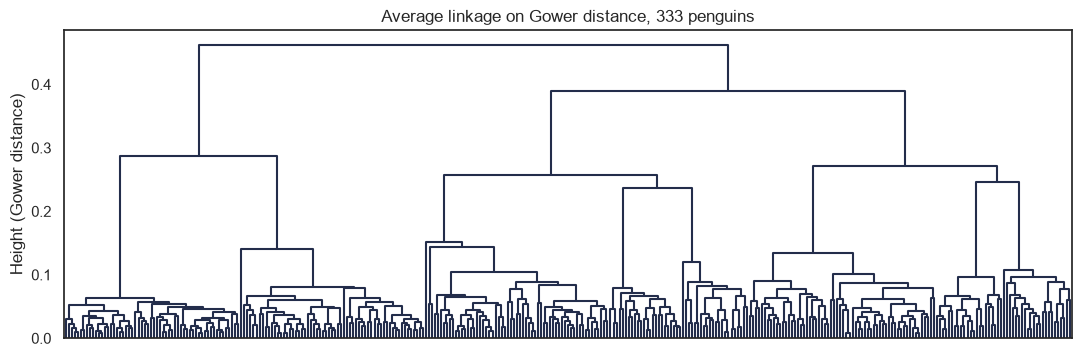

In [12]:
G = gower_matrix(full, numeric=feats, categorical=["island", "sex"])

#Note: linkage wants the distances in condensed form (ie just the upper triangle)
# The squareform function achieves this. 
Z_gower = linkage(squareform(G, checks=False), method="average")

fig, ax = plt.subplots(figsize=(13, 4))
dendrogram(Z_gower, no_labels=True, color_threshold=0, above_threshold_color="#232D4B", ax=ax)
ax.set_ylabel("Height (Gower distance)")
ax.set_title("Average linkage on Gower distance, 333 penguins")
plt.show()

In [13]:
gower_labels = fcluster(Z_gower, t=3, criterion="maxclust")
print(f"Average silhouette: {silhouette_score(G, gower_labels, metric='precomputed'):.3f}")
pd.crosstab(gower_labels, full["species"], rownames=["cluster"])

Average silhouette: 0.503


species,Adelie,Chinstrap,Gentoo
cluster,,,
1,0,0,119
2,73,34,0
3,73,34,0


The same model in sklearn: pass the full distance matrix with `metric="precomputed"` and any linkage except Ward.

In [14]:
sk_labels = AgglomerativeClustering(n_clusters=3, metric="precomputed", linkage="average").fit_predict(G)
pd.crosstab(sk_labels, gower_labels, rownames=["sklearn"], colnames=["scipy"])

scipy,1,2,3
sklearn,,,
0,119,0,0
1,0,0,107
2,0,107,0


Clusters 2 and 3 don't separate Adelie from Chinstrap at all: they split them 73/34 and 73/34. What is going on? Let's cross-tab the clusters with island and sex:

In [15]:
pd.crosstab(gower_labels, [full["island"], full["sex"]], rownames=["cluster"])

island  Biscoe       Dream      Torgersen     
sex     female male female male    female male
cluster                                       
1           58   61      0    0         0    0
2           22    0     61    0        24    0
3            0   22      0   62         0   23

Cluster 1 is the Biscoe Gentoos. (Remember, only Gentoos are on that island.) Clusters 2 and 3 are **female** and **male** Adelie/Chinstrap penguins: the clustering split on sex but not species. Remember, we did not include species in our clustering because we are pretending that we don't know the species, and are trying to investigate different clustering methods to see if species falls out as a natural grouping. In this case, it didn't happen. 

Why might sex be the more dominant variable here? A categorical mismatch always adds the full 1 to its variable's term, while two penguins of different species typically differ by only a fraction of the range on each numeric feature. So the categorical variables can dominate a Gower distance.

If we wanted to explore this in more detail, we could do the following: 

1. Drop `sex` from the clustering
2. Give the categorical variables smaller weights $w_k$

These clusters might be absolutely fine, but in any analysis, when you notice groupings like this, it bears further investigation. 

### Linkage: distance between clusters (slides 53–57)

| Linkage | Distance between clusters A and B | Tends to produce |
|---|---|---|
| Single | smallest pairwise distance | long, chained clusters |
| Complete | largest pairwise distance | compact clusters |
| Average | mean of all pairwise distances | a compromise |
| Ward | increase in WCSS from merging | compact clusters, like K-means |

**Ward vs. K-means.** Ward's method merges the pair of clusters that increases total WCSS the least, the same objective as K-means built greedily. So the two often agree:

In [16]:
# Remember that Xs is the transformed numeric features that we used for K means
df["ward"] = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(Xs)
agree = pd.crosstab(df["ward"], df["kmeans"], rownames=["Ward"], colnames=["K-means"])
print(f"Agreement: {agree.max(axis=1).sum()} of {len(df)} penguins")
agree

Agreement: 312 of 342 penguins


K-means,A,B,C
Ward,,,
0,0,132,30
1,123,0,0
2,0,0,57


In [17]:
pd.crosstab(df["ward"], df["species"], rownames=["Ward"])

species,Adelie,Chinstrap,Gentoo
Ward,,,
0,151,11,0
1,0,0,123
2,0,57,0


**Linkage type changes the tree.** 

Now let's look in more detail at how linkage type changes the dendrogram. To do this, we will sample 45 penguins (15 per species) from our dataset, so the dendrograms are more readable. We will use only the numeric features to calculate linkages

In [18]:
rng = np.random.default_rng(5)
samp = np.concatenate([rng.choice(np.where(species_code == s)[0], 15, replace=False) for s in range(3)])
S = Xs[samp]

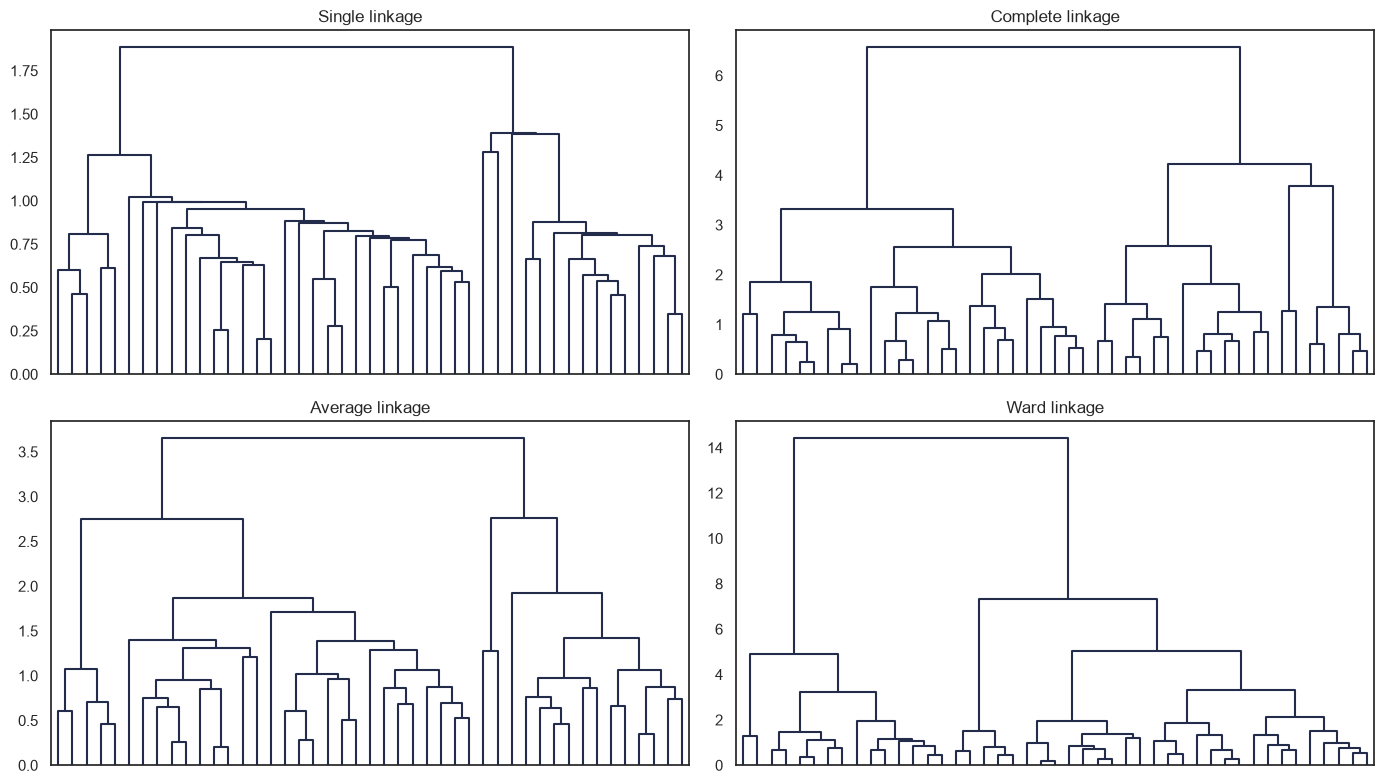

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, method in zip(axes.flat, ["single", "complete", "average", "ward"]):
    dendrogram(linkage(S, method=method), no_labels=True, color_threshold=0,
               above_threshold_color="#232D4B", ax=ax)
    ax.set_title(f"{method.capitalize()} linkage")
plt.tight_layout()
plt.show()

For different linkage types, we can calculate the number of pengins in each cluster for a specified number of clusters. 

In [20]:
rows = []
for method in ["single", "complete", "average", "ward"]:
    for k in [2, 3]:
        labs = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(Xs)
        rows.append({"linkage": method, "K": k, "cluster sizes": sorted(np.bincount(labs), reverse=True),
                     "avg silhouette": round(silhouette_score(Xs, labs), 3)})
pd.DataFrame(rows)

,linkage,K,cluster sizes,avg silhouette
0,single,2,"[341, 1]",0.253
1,single,3,"[218, 123, 1]",0.469
2,complete,2,"[219, 123]",0.532
3,complete,3,"[165, 123, 54]",0.452
4,average,2,"[219, 123]",0.532
5,average,3,"[219, 119, 4]",0.442
6,ward,2,"[219, 123]",0.532
7,ward,3,"[162, 123, 57]",0.454


With K = 2, single linkage puts 341 penguins in one cluster and 1 in the other.

**Back to the moons.** Chaining (adding one point at a time to a cluster, as we do for single linkage) is a weakness on the penguin dataset, but it is exactly what we need for the moons: single linkage follows each curve point by point.

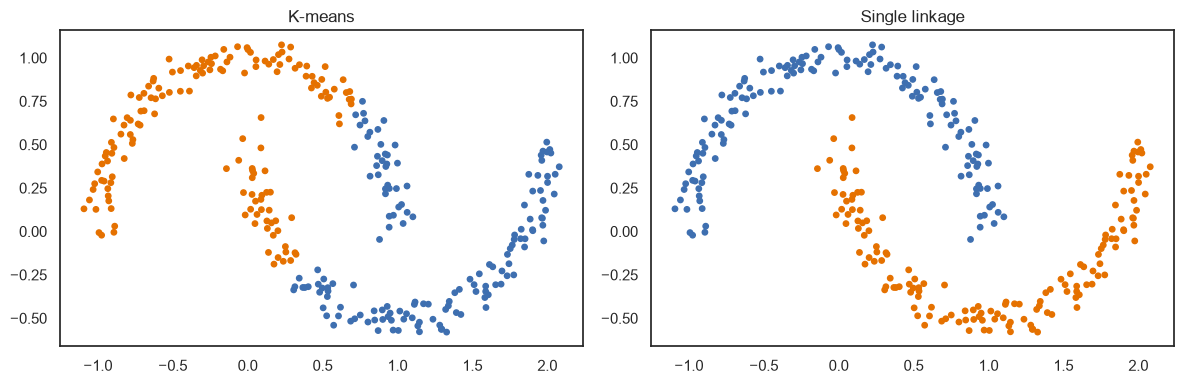

In [21]:
moon_single = AgglomerativeClustering(n_clusters=2, linkage="single").fit_predict(Xm)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, labs, title in [(axes[0], moon_km.labels_, "K-means"), (axes[1], moon_single, "Single linkage")]:
    ax.scatter(Xm[:, 0], Xm[:, 1], c=[PALETTE[k] for k in labs], s=15)
    ax.set_title(title)
plt.tight_layout()
plt.show()

### How many clusters? (slides 58–61)

#### Cutting the tree (slide 59)

One dendrogram gives every number of clusters: a horizontal cut at height $h$ gives the clusters below it. 

In the example below we use the same 45 penguins (15 per species), all four standardized features, and Ward's method.

Four largest merge heights: [14.43  7.32  5.03  4.92]


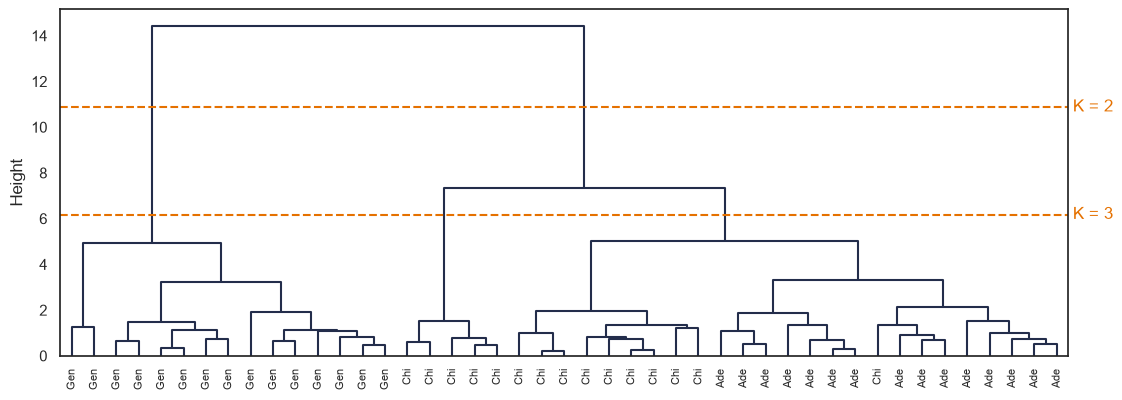

In [22]:
Z_ward = linkage(S, method="ward")

heights = np.sort(Z_ward[:, 2])[::-1]
print("Four largest merge heights:", heights[:4].round(2))
cut2, cut3 = (heights[0] + heights[1]) / 2, (heights[1] + heights[2]) / 2

fig, ax = plt.subplots(figsize=(13, 4.5))
dendrogram(Z_ward, labels=df["species"].iloc[samp].str[:3].to_list(), color_threshold=0,
           above_threshold_color="#232D4B", leaf_font_size=8, ax=ax)
for h, lab in [(cut2, "K = 2"), (cut3, "K = 3")]:
    ax.axhline(h, color="#E57100", ls="--")
    ax.text(ax.get_xlim()[1], h, " " + lab, color="#E57100", va="center")
ax.set_ylabel("Height")
plt.show()

Leaf labels are the first three letters of the species (not used for clustering). The biggest vertical gap is between the last two merges, which favors cutting at K = 2. `fcluster` does the cut for us:

In [23]:
for k in [2, 3]:
    labs = fcluster(Z_ward, t=k, criterion="maxclust")
    print(f"K = {k}")
    print(pd.crosstab(labs, df["species"].iloc[samp].to_numpy(), rownames=["cluster"], colnames=["species"]), "\n")

K = 2
species  Adelie  Chinstrap  Gentoo
cluster                           
1             0          0      15
2            15         15       0 

K = 3
species  Adelie  Chinstrap  Gentoo
cluster                           
1             0          0      15
2             0          5       0
3            15         10       0 



#### Silhouette scores (slide 61)

The silhouette works for hierarchical clustering too. For Ward on all 342 penguins:

In [24]:
pd.Series({k: round(silhouette_score(Xs, AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Xs)), 3)
           for k in range(2, 9)}, name="avg silhouette").rename_axis("K")

K
2    0.532
3    0.454
4    0.418
5    0.363
6    0.335
7    0.305
8    0.259
Name: avg silhouette, dtype: float64